# Single-Stock Risk Analysis Report

This parameterized notebook loads validated market data and calculates risk metrics for one stock over a requested date range.

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/hb525/Desktop/MFE PreProgram/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Hiba_Lina_Ben_Khaddah/data/data.db"


In [3]:
from contextlib import closing
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display

%matplotlib inline

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Load and validate the cleaned data

In [4]:
database = Path(db_path).expanduser().resolve()

if not database.is_file():
    raise FileNotFoundError(f"Database not found: {database}")

ticker = str(ticker).strip().upper()
start = pd.Timestamp(start_date)
end = pd.Timestamp(end_date)

if start > end:
    raise ValueError("start_date must be on or before end_date.")

query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ?
  AND ts >= ?
  AND ts <= ?
ORDER BY ts
"""

with closing(
    sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)
) as connection:
    stock_data = pd.read_sql_query(
        query,
        connection,
        params=(
            ticker,
            start.strftime("%Y-%m-%d"),
            end.strftime("%Y-%m-%d"),
        ),
        parse_dates=["ts"],
        index_col="ts",
    )

if len(stock_data) < 21:
    raise ValueError(
        f"{ticker}: at least 21 prices are required to calculate "
        f"20 returns; found {len(stock_data)}."
    )

print(
    f"{ticker} from {start_date} to {end_date}: "
    f"{len(stock_data)} trading days"
)
print(
    f"Actual observations: {stock_data.index.min().date()} "
    f"to {stock_data.index.max().date()}"
)

display(stock_data.head())
display(stock_data.tail())

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 to 2024-11-29


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400
2024-06-06,167.38,168.44,166.80,168.20,165.44,2207263
2024-06-07,168.18,171.31,168.06,170.01,167.22,3475500


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,223.35,227.20,220.89,222.97,222.97,5320740
2024-11-25,223.35,226.42,222.65,226.13,226.13,7189300
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


### Input quality check

Before calculating returns, we verify that the selected cleaned data still has valid prices, OHLC relationships, volume, and unique dates.

In [5]:
def quality_flags(frame):
    """Flag invalid values, OHLC relationships, and duplicate dates."""
    price_columns = ["open", "high", "low", "close", "adj_close"]

    flags = pd.DataFrame(index=frame.index)

    flags["missing_or_nonfinite"] = ~np.isfinite(
        frame[price_columns + ["volume"]]
    ).all(axis=1)

    flags["nonpositive_price"] = (
        frame[price_columns].le(0).any(axis=1)
    )

    flags["invalid_ohlc_bounds"] = (
        frame["high"].lt(frame[["open", "close"]].max(axis=1))
        | frame["low"].gt(frame[["open", "close"]].min(axis=1))
        | frame["high"].lt(frame["low"])
    )

    flags["negative_volume"] = frame["volume"].lt(0)
    flags["duplicate_date"] = frame.index.duplicated(keep=False)

    return flags

In [6]:
quality = quality_flags(stock_data)
quality_summary = quality.sum()

display(quality_summary.to_frame("issue_count"))

data_quality_ok = not quality.any().any()

if not data_quality_ok:
    raise ValueError(
        f"Input data quality checks failed: "
        f"{quality_summary.to_dict()}"
    )

print("Input data quality checks passed.")

,issue_count
missing_or_nonfinite,0
nonpositive_price,0
invalid_ohlc_bounds,0
negative_volume,0
duplicate_date,0


Input data quality checks passed.


## 2. Calculate risk metrics

Returns are calculated from adjusted close because it accounts for corporate actions such as stock splits and dividends. Log returns are used for volatility, Sharpe ratio, and daily-return statistics.

In [7]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from a sorted positive price series."""
    return np.log(prices / prices.shift(1))

In [8]:
stock_data["log_return"] = calculate_returns(
    stock_data["adj_close"]
)

# The first return is undefined because there is no previous price.
assert pd.isna(stock_data["log_return"].iloc[0])
assert np.isfinite(
    stock_data["log_return"].iloc[1:]
).all()

display(
    stock_data[["adj_close", "log_return"]].head()
)

print(
    "Number of nonmissing daily returns:",
    stock_data["log_return"].notna().sum(),
)

,adj_close,log_return
ts,,
2024-06-03,162.57,NaN
2024-06-04,163.09,0.003194
2024-06-05,164.63,0.009398
2024-06-06,165.44,0.004908
2024-06-07,167.22,0.010702


Number of nonmissing daily returns: 125


### Rolling volatility

Rolling volatility measures how variable the most recent 20 daily log returns are. It is annualized using 252 trading days per year.

In [9]:
def calculate_volatility(
    returns: pd.Series,
    window: int = 20,
) -> pd.Series:
    """Calculate annualized rolling volatility from daily log returns."""
    return (
        returns
        .rolling(window=window, min_periods=window)
        .std(ddof=1)
        * np.sqrt(252)
    )

In [10]:
volatility_window = 20

stock_data["volatility"] = calculate_volatility(
    stock_data["log_return"],
    window=volatility_window,
)

# Preserve the warm-up period instead of replacing it with zero.
assert stock_data["volatility"].iloc[:volatility_window].isna().all()
assert np.isfinite(
    stock_data["volatility"].iloc[volatility_window:]
).all()

display(
    stock_data[
        ["log_return", "volatility"]
    ].head(volatility_window + 2)
)

print(
    "Mean rolling annualized volatility:",
    f"{stock_data['volatility'].mean():.2%}",
)

,log_return,volatility
ts,,
2024-06-03,NaN,NaN
2024-06-04,0.003194,NaN
2024-06-05,0.009398,NaN
2024-06-06,0.004908,NaN
2024-06-07,0.010702,NaN
2024-06-10,0.002151,NaN
2024-06-11,-0.006225,NaN
2024-06-12,-0.001923,NaN
2024-06-13,0.000722,NaN


Mean rolling annualized volatility: 19.93%


The first 20 rows of volatility should be NaN. That is intentional: a complete 20-return window is not available yet.

### Drawdown and maximum drawdown

Drawdown measures the percentage decline from the highest adjusted close
observed up to each date. The most negative drawdown is the maximum drawdown.

In [11]:
def calculate_max_drawdown(
    prices: pd.Series,
) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak

In [12]:
stock_data["drawdown"] = calculate_max_drawdown(
    stock_data["adj_close"]
)

maximum_drawdown = stock_data["drawdown"].min()
maximum_drawdown_date = stock_data["drawdown"].idxmin()

assert stock_data["drawdown"].le(0).all()
assert stock_data["drawdown"].iloc[0] == 0

display(
    stock_data[
        ["adj_close", "drawdown"]
    ].head()
)

print(f"Maximum drawdown: {maximum_drawdown:.2%}")
print(
    "Maximum drawdown date:",
    maximum_drawdown_date.date(),
)

,adj_close,drawdown
ts,,
2024-06-03,162.57,0.0
2024-06-04,163.09,0.0
2024-06-05,164.63,0.0
2024-06-06,165.44,0.0
2024-06-07,167.22,0.0


Maximum drawdown: -12.90%
Maximum drawdown date: 2024-10-30


### Sharpe ratio

The Sharpe ratio compares annualized average log return with the 2% annual
risk-free rate, relative to annualized return volatility. It is undefined when
there are insufficient returns or zero volatility.

In [13]:
def calculate_sharpe_ratio(
    returns: pd.Series,
    risk_free_rate: float = 0.02,
) -> float:
    """Calculate the annualized Sharpe ratio from daily log returns."""
    observed_returns = returns.dropna()
    return_std = observed_returns.std(ddof=1)

    if (
        len(observed_returns) < 2
        or not np.isfinite(return_std)
        or np.isclose(return_std, 0)
    ):
        return np.nan

    return (
        observed_returns.mean() * 252
        - risk_free_rate
    ) / (
        return_std * np.sqrt(252)
    )

In [14]:
metric_returns = stock_data["log_return"].dropna()

sharpe_ratio = calculate_sharpe_ratio(
    metric_returns,
    risk_free_rate=0.02,
)

if pd.isna(sharpe_ratio):
    print("Sharpe ratio: N/A")
else:
    print(f"Sharpe ratio: {sharpe_ratio:.2f}")

Sharpe ratio: 3.22


## 3. Visualize the risk report

The report uses adjusted prices, daily log returns, 20-day annualized rolling
volatility, and drawdown. Rolling warm-up periods remain missing rather than
being filled with zero.

In [15]:
moving_average_window = 50

stock_data["moving_average_50"] = (
    stock_data["adj_close"]
    .rolling(
        window=moving_average_window,
        min_periods=moving_average_window,
    )
    .mean()
)

mean_volatility = stock_data["volatility"].mean()

first_moving_average_date = (
    stock_data["moving_average_50"]
    .first_valid_index()
)

if first_moving_average_date is None:
    assert stock_data["moving_average_50"].isna().all()

    print(
        "50-day moving average unavailable: "
        f"the report contains only {len(stock_data)} prices."
    )
else:
    # A 50-price average first becomes available on observation 50.
    assert (
        stock_data["moving_average_50"]
        .iloc[: moving_average_window - 1]
        .isna()
        .all()
    )

    assert np.isfinite(
        stock_data["moving_average_50"]
        .iloc[moving_average_window - 1 :]
    ).all()

    print(
        "First available 50-day moving average:",
        first_moving_average_date.date(),
    )

print(
    "Mean rolling volatility threshold:",
    f"{mean_volatility:.2%}",
)

First available 50-day moving average: 2024-08-13
Mean rolling volatility threshold: 19.93%


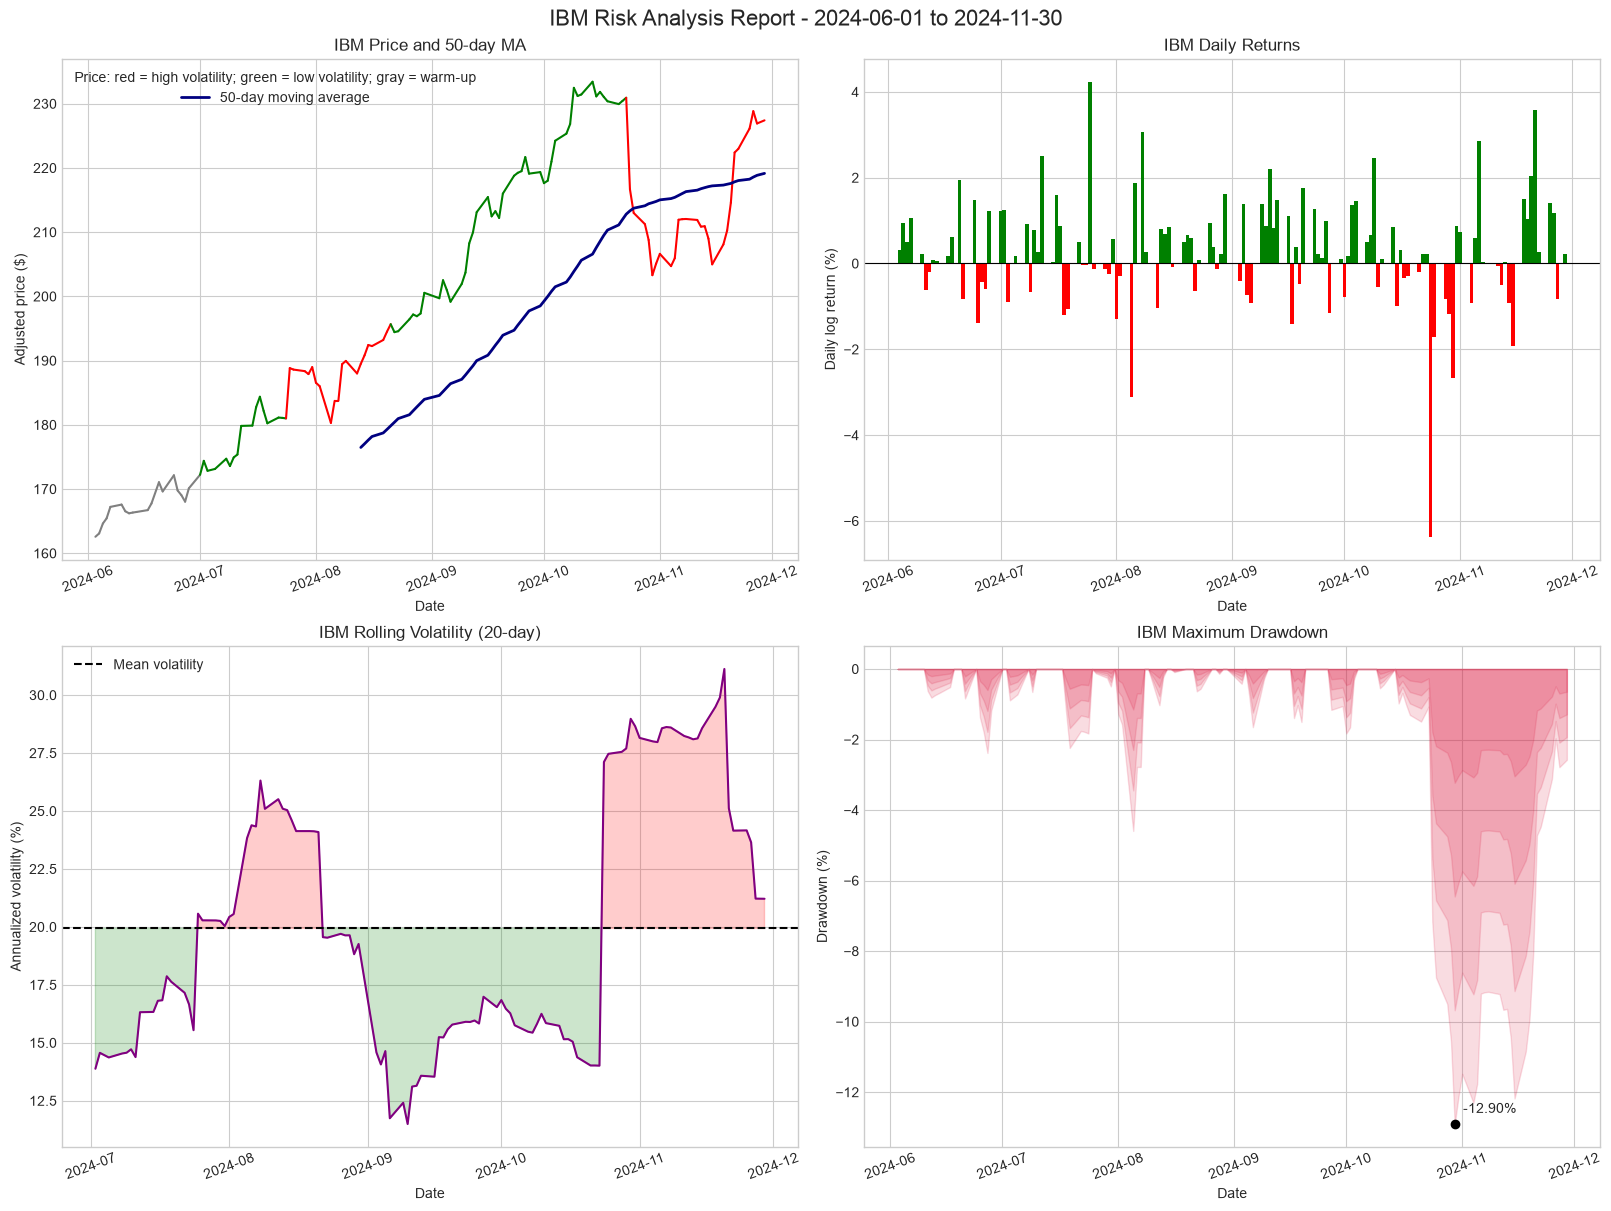

In [16]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 12),
    layout="constrained",
)

fig.suptitle(
    f"{ticker} Risk Analysis Report - "
    f"{start_date} to {end_date}",
    fontsize=16,
)

# Top left: adjusted price colored by rolling volatility.
price_ax = axes[0, 0]

for position in range(1, len(stock_data)):
    volatility = stock_data["volatility"].iloc[position]

    if pd.isna(volatility):
        color = "gray"
    elif volatility > mean_volatility:
        color = "red"
    else:
        color = "green"

    price_ax.plot(
        stock_data.index[position - 1 : position + 1],
        stock_data["adj_close"].iloc[
            position - 1 : position + 1
        ],
        color=color,
        linewidth=1.5,
    )

price_ax.plot(
    stock_data.index,
    stock_data["moving_average_50"],
    color="navy",
    linewidth=2,
    label="50-day moving average",
)

price_ax.set_title(
    f"{ticker} Price and 50-day MA"
)
price_ax.set_ylabel("Adjusted price ($)")
price_ax.legend(
    title=(
        "Price: red = high volatility; "
        "green = low volatility; gray = warm-up"
    )
)

# Top right: daily log returns.
return_ax = axes[0, 1]

return_colors = np.where(
    stock_data["log_return"].gt(0),
    "green",
    np.where(
        stock_data["log_return"].lt(0),
        "red",
        "gray",
    ),
)

return_ax.bar(
    stock_data.index,
    stock_data["log_return"] * 100,
    width=1,
    color=return_colors,
)

return_ax.axhline(
    0,
    color="black",
    linewidth=0.8,
)

return_ax.set_title(
    f"{ticker} Daily Returns"
)
return_ax.set_ylabel("Daily log return (%)")

# Bottom left: annualized rolling volatility.
volatility_ax = axes[1, 0]
volatility_percent = stock_data["volatility"] * 100
mean_volatility_percent = mean_volatility * 100

volatility_ax.plot(
    stock_data.index,
    volatility_percent,
    color="purple",
    linewidth=1.5,
)

volatility_ax.axhline(
    mean_volatility_percent,
    color="black",
    linestyle="--",
    label="Mean volatility",
)

high_volatility = (
    stock_data["volatility"].notna()
    & stock_data["volatility"].gt(mean_volatility)
)

low_volatility = (
    stock_data["volatility"].notna()
    & stock_data["volatility"].le(mean_volatility)
)

volatility_ax.fill_between(
    stock_data.index,
    volatility_percent,
    mean_volatility_percent,
    where=high_volatility,
    color="red",
    alpha=0.2,
    interpolate=True,
)

volatility_ax.fill_between(
    stock_data.index,
    volatility_percent,
    mean_volatility_percent,
    where=low_volatility,
    color="green",
    alpha=0.2,
    interpolate=True,
)

volatility_ax.set_title(
    f"{ticker} Rolling Volatility (20-day)"
)
volatility_ax.set_ylabel(
    "Annualized volatility (%)"
)
volatility_ax.legend()

# Bottom right: per-date drawdown.
drawdown_ax = axes[1, 1]
drawdown_percent = stock_data["drawdown"] * 100

# Layered transparent fills create a red/pink gradient.
for fraction in [1.0, 0.75, 0.5, 0.25]:
    drawdown_ax.fill_between(
        stock_data.index,
        drawdown_percent * fraction,
        0,
        color="crimson",
        alpha=0.15,
    )

drawdown_ax.scatter(
    [maximum_drawdown_date],
    [maximum_drawdown * 100],
    color="black",
    zorder=3,
)

drawdown_ax.annotate(
    f"{maximum_drawdown:.2%}",
    (
        maximum_drawdown_date,
        maximum_drawdown * 100,
    ),
    xytext=(6, 8),
    textcoords="offset points",
)

drawdown_ax.set_title(
    f"{ticker} Maximum Drawdown"
)
drawdown_ax.set_ylabel("Drawdown (%)")

# Apply consistent formatting to every subplot.
for axis in axes.flat:
    axis.set_xlabel("Date")
    axis.grid(True)
    axis.tick_params(
        axis="x",
        labelrotation=20,
    )

plt.show()

## 4. Summary statistics

The calculations retain fractional values internally. Percentages are applied
only when displaying the final table.

In [17]:
number_of_returns = len(metric_returns)

total_return = (
    stock_data["adj_close"].iloc[-1]
    / stock_data["adj_close"].iloc[0]
    - 1
)

annualized_return = np.expm1(
    metric_returns.sum()
    * 252
    / number_of_returns
)

annualized_volatility = (
    metric_returns.std(ddof=1)
    * np.sqrt(252)
)

best_day = metric_returns.max()
worst_day = metric_returns.min()

# Zero-return days remain in the denominator.
positive_days = metric_returns.gt(0).mean()

up_days = metric_returns.loc[
    metric_returns.gt(0)
]
down_days = metric_returns.loc[
    metric_returns.lt(0)
]

average_up_day = up_days.mean()
average_down_day = down_days.mean()

# Log returns compound to the same whole-period total return.
assert np.isclose(
    np.expm1(metric_returns.sum()),
    total_return,
)

In [18]:
summary_metrics = pd.Series(
    {
        "Total Return": total_return,
        "Annualized Return": annualized_return,
        "Annualized Volatility": annualized_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown": maximum_drawdown,
        "Best Day": best_day,
        "Worst Day": worst_day,
        "Positive Days": positive_days,
        "Average Up Day": average_up_day,
        "Average Down Day": average_down_day,
    },
    name="Value",
)

percentage_metrics = {
    "Total Return",
    "Annualized Return",
    "Annualized Volatility",
    "Maximum Drawdown",
    "Best Day",
    "Worst Day",
    "Positive Days",
    "Average Up Day",
    "Average Down Day",
}

signed_percentage_metrics = {
    "Total Return",
    "Annualized Return",
    "Maximum Drawdown",
    "Best Day",
    "Worst Day",
    "Average Up Day",
    "Average Down Day",
}

display_summary = pd.DataFrame(
    {
        "Metric": summary_metrics.index,
        "Value": [
            (
                "N/A"
                if pd.isna(value)
                else f"{value:+.2%}"
                if metric in signed_percentage_metrics
                else f"{value:.2%}"
                if metric in percentage_metrics
                else f"{value:.2f}"
            )
            for metric, value in summary_metrics.items()
        ],
    }
)

display(display_summary)

,Metric,Value
0,Total Return,+39.88%
1,Annualized Return,+96.73%
2,Annualized Volatility,20.42%
3,Sharpe Ratio,3.22
4,Maximum Drawdown,-12.90%
5,Best Day,+4.24%
6,Worst Day,-6.37%
7,Positive Days,63.20%
8,Average Up Day,+0.95%
9,Average Down Day,-0.92%


## 5. Export report results

Named numeric outputs are exported with Scrapbook so the batch script can
collect results from successful reports without parsing displayed text.

In [19]:
stats = {
    "ticker": ticker,
    "requested_start_date": start_date,
    "requested_end_date": end_date,
    "actual_start_date": (
        stock_data.index.min().strftime("%Y-%m-%d")
    ),
    "actual_end_date": (
        stock_data.index.max().strftime("%Y-%m-%d")
    ),
    "trading_days": len(stock_data),
    "avg_daily_return": metric_returns.mean(),
    "avg_volatility": mean_volatility,
    "max_drawdown": maximum_drawdown,
    "sharpe_ratio": sharpe_ratio,
    "total_return": total_return,
    "annualized_return": annualized_return,
    "annualized_volatility": annualized_volatility,
}

# Export the fields needed by the portfolio summary.
sb.glue("ticker", ticker)
sb.glue("start_date", start_date)
sb.glue("end_date", end_date)
sb.glue("trading_days", len(stock_data))
sb.glue("avg_daily_return", stats["avg_daily_return"])
sb.glue("avg_volatility", stats["avg_volatility"])
sb.glue("max_drawdown", stats["max_drawdown"])
sb.glue("sharpe_ratio", stats["sharpe_ratio"])
sb.glue("total_return", stats["total_return"])
sb.glue("data_quality_ok", data_quality_ok)

# Convert NumPy scalar values before exporting the dictionary.
serializable_stats = {
    key: (
        value.item()
        if isinstance(value, np.generic)
        else value
    )
    for key, value in stats.items()
}

sb.glue("stats", serializable_stats)
sb.glue(
    "analysis_plot",
    fig,
    encoder="display",
    display=False,
)

print("Named report results exported successfully.")

Named report results exported successfully.


## Conclusion

This report analyzed the requested stock using validated adjusted prices. It
reported the stock’s actual available coverage, calculated log returns,
annualized volatility, drawdown, Sharpe ratio, and summary statistics, and
exported named results for the automated portfolio pipeline.